## Data Preprocessing with Scanpy

In [1]:
# Core scverse libraries
from __future__ import annotations

import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import math
import os

/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


In [2]:
# Set verbosity to see more log output
sc.settings.verbosity = 4

### Reading in Data from muscle droplet folder(s) into an AnnData object

In [3]:
# Load data from 10X Genomics format directory using scanpys read_10x_mtx function


# sc.read_10x_mtx("droplet/Muscle-10X_P7_14"),
# sc.read_10x_mtx("droplet/Muscle-10X_P7_15"),

# checking how visualizations look when muscle_droplet_annotation.csv used for cell type labels instead of annotations_droplet.csv

tiss = ad.concat([
    sc.read_10x_mtx("../droplet/Muscle-10X_P7_14"),
    sc.read_10x_mtx("../droplet/Muscle-10X_P7_15"),
])

tiss.obs_names_make_unique()

tiss.obs


    reading ../droplet/Muscle-10X_P7_14/matrix.mtx
--> This might be very slow. Consider passing `cache=True`, which enables much faster reading from a cache file.
    reading ../droplet/Muscle-10X_P7_15/matrix.mtx
--> This might be very slow. Consider passing `cache=True`, which enables much faster reading from a cache file.


/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/anndata/_core/anndata.py:1792: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


""
AAACCTGCAGGTCCAC-1
AAACCTGCATCAGTAC-1
AAACCTGGTGCCTGGT-1
AAACCTGGTTATCACG-1
AAACCTGTCCCAGGTG-1
...
TTTGTCAAGCCAGAAC-1
TTTGTCACAGCCTTGG-1
TTTGTCAGTAAGGGCT-1
TTTGTCAGTCTCCACT-1


In [4]:
tiss.obs

""
AAACCTGCAGGTCCAC-1
AAACCTGCATCAGTAC-1
AAACCTGGTGCCTGGT-1
AAACCTGGTTATCACG-1
AAACCTGTCCCAGGTG-1
...
TTTGTCAAGCCAGAAC-1
TTTGTCACAGCCTTGG-1
TTTGTCAGTAAGGGCT-1
TTTGTCAGTCTCCACT-1


### Quality Control using Organ Annotation Vignette that described quality control steps done in the study 
https://static-content.springer.com/esm/art%3A10.1038%2Fs41586-018-0590-4/MediaObjects/41586_2018_590_MOESM4_ESM.pdf

In [5]:
sc.pp.filter_cells(tiss, min_genes=500)
sc.pp.filter_cells(tiss, min_counts=1000)

tiss.obs

filtered out 6 cells that have less than 500 genes expressed


,n_genes,n_counts
AAACCTGCAGGTCCAC-1,1934,6372.0
AAACCTGCATCAGTAC-1,925,1825.0
AAACCTGGTGCCTGGT-1,1436,3907.0
AAACCTGGTTATCACG-1,948,2527.0
AAACCTGTCCCAGGTG-1,861,2458.0
...,...,...
TTTGTCAAGCCAGAAC-1,1091,2683.0
TTTGTCACAGCCTTGG-1,1239,2589.0
TTTGTCAGTAAGGGCT-1,2439,9056.0
TTTGTCAGTCTCCACT-1,2296,8244.0


## Normalization

In [6]:
# Normalizing to median total counts
sc.pp.normalize_total(tiss, target_sum=1e4)

# Logarithmize the data
sc.pp.log1p(tiss)

# Scale (center to 0, unit variance)
sc.pp.scale(tiss)


normalizing counts per cell
    finished (0:00:00)


/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/functools.py:912: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


## Feature Selection
By including only the most informative genes. The genes that vary the most in the data.

In [7]:
sc.pp.highly_variable_genes(tiss, flavor="seurat", max_mean=math.inf, min_disp=0.5)

extracting highly variable genes
    finished (0:00:00)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)


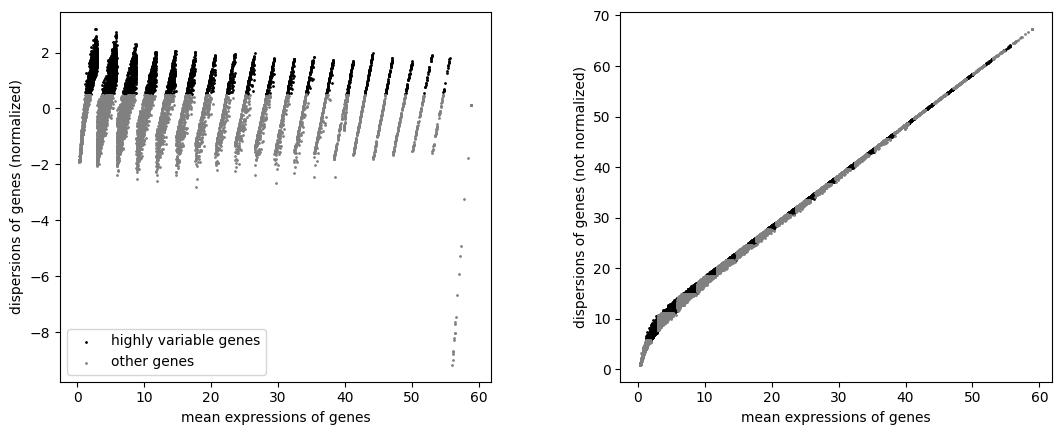

In [8]:
sc.pl.highly_variable_genes(tiss)

In [9]:
# Keep only HVGs
tiss = tiss[:, tiss.var.highly_variable]

tiss.var

,mean,std,highly_variable,means,dispersions,dispersions_norm
Rgs20,0.002773,0.048862,True,14.675995,22.232358,1.182056
Adhfe1,0.006528,0.083308,True,14.667391,23.058882,2.043244
3110035E14Rik,0.000710,0.033808,True,40.420952,48.658314,0.505434
Mybl1,0.001350,0.042835,True,34.194594,42.614565,0.541879
Vcpip1,0.051892,0.245804,True,2.391937,6.953168,1.075515
...,...,...,...,...,...,...
Prps2,0.068620,0.295446,True,2.202362,7.051296,1.123581
Arhgap6,0.056385,0.246600,True,2.596124,7.986653,1.581747
Hccs,0.100665,0.346275,True,1.693973,6.398678,0.803909
G530011O06Rik,0.137374,0.445855,True,1.893709,6.743291,0.972711


## Dimensionality Reduction
Through PCA

In [10]:
# PCA
sc.pp.pca(tiss)


computing PCA
    with n_comps=50
    finished (0:00:02)
    and added
    'X_pca', the PCA coordinates (adata.obs)
    'PCs', the loadings (adata.varm)
    'pca_variance', the variance / eigenvalues (adata.uns['pca'])
    'pca_variance_ratio', the variance ratio (adata.uns['pca'])


/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/scanpy/preprocessing/_pca/__init__.py:384: ImplicitModificationWarning: Setting element `.obsm['X_pca']` of view, initializing view as actual.
  adata.obsm[key_obsm] = x_pca


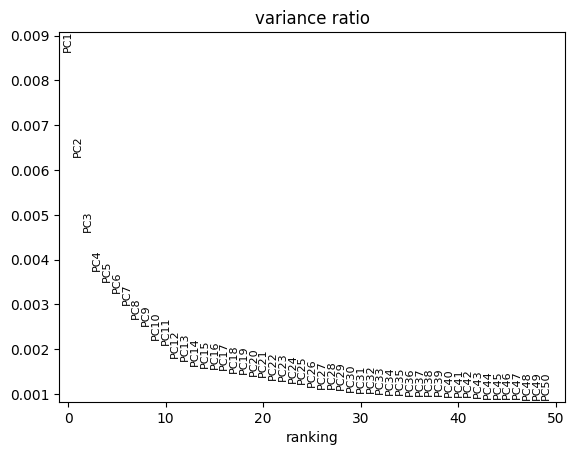

In [11]:
sc.pl.pca_variance_ratio(tiss, n_pcs=50)

## reading in annotations


In [12]:
muscle_annotations = pd.read_csv("../annotations/Muscle_droplet_annotation.csv")

y = muscle_annotations["cell_ontology_class"].values
y


array(['endothelial cell', 'endothelial cell', 'unknown', ...,
       'mesenchymal stem cell', 'mesenchymal stem cell',
       'skeletal muscle satellite cell'], shape=(4536,), dtype=object)

In [13]:
tiss.obs["cell_ontology_class"] = y
tiss.obs

ValueError: Length of values (4536) does not match length of index (4537)

## Clustering


In [ ]:
# Compute t-SNE
sc.pp.neighbors(tiss, n_neighbors=15, n_pcs=10)

# below to mimic organ vignette supplementary preprocessing steps (using R, Seurat for FindClusters)
sc.tl.louvain(tiss, resolution=0.4) 

In [ ]:
#inspection based on above ouptput
tiss.obs

## Visualizing Clusters Using tSNE

In [ ]:
#computer tSNE
sc.tl.tsne(tiss, n_pcs=10, perplexity=30, random_state=0)

# Plot tSNE
sc.pl.tsne(tiss, color="louvain", title="Clustering from Louvain", legend_loc='on data')

# Plot tSNE
sc.pl.tsne(tiss, color="cell_ontology_class", title="True Cell Types", legend_loc='on data')


## Machine Learning related preprocessing

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler


# Encode labels
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# Train-test split
X_train, X_test, Y_train, Y_test = train_test_split(
    tiss.X, y_encoded, test_size=0.2, random_state=42
)

X_train.shape, X_test.shape, Y_train.shape, Y_test.shape

## scikit-learn Machine Learning Classifiers

In [ ]:
# --- CLASSIFIERS ---
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

# optional xgboost support
try:
    from xgboost import XGBClassifier
    XGBOOST_AVAILABLE = True
except ImportError:
    XGBOOST_AVAILABLE = False

In [ ]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "SVM (RBF Kernel)": SVC(probability=True),
    "Random Forest": RandomForestClassifier(n_estimators=200),
    "Gradient Boosting": GradientBoostingClassifier(),
    "KNN (k=5)": KNeighborsClassifier(),
    "Naive Bayes": GaussianNB()
}

In [ ]:
from sklearn.metrics import classification_report, accuracy_score

# Train + evaluate each model
for name, model in models.items():
    model.fit(X_train, Y_train)
    preds = model.predict(X_test)
    acc = accuracy_score(Y_test, preds)

    print("=" * 60)
    print(f"📌 Model: {name}")
    print(f"✅ Accuracy: {acc:.4f}")
    print("\nClassification Report:")
    print(classification_report(Y_test, preds))

## Pytorch Neural Network

In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader

# Normalize and scale
# scaler = StandardScaler(with_mean=False)
# X_scaled = scaler.fit_transform(X)
# commented out because data is already normalized and scaled using scanpy

# Convert to torch tensors
# train
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(Y_train, dtype=torch.long)
# test
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(Y_test, dtype=torch.long)



In [ ]:
class SingleCellDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

dataset = SingleCellDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(dataset, batch_size=128, shuffle=True)


In [ ]:
import torch.nn as nn
import torch.nn.functional as F

class Classifier(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, 10)
        self.fc2 = nn.Linear(10, 10)
        self.fc3 = nn.Linear(10, num_classes)
        # self.dropout = nn.Dropout(0.3)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        # x = self.dropout(x)
        x = F.relu(self.fc2(x))
        # x = self.dropout(x)
        x = self.fc3(x)
        return x


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = Classifier(input_dim=X_train_tensor.shape[1], num_classes=len(le.classes_)).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

for epoch in range(10):
    model.train()
    total_loss = 0
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        
        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    print(f"Epoch {epoch+1}, Loss: {total_loss/len(train_loader):.4f}")


In [ ]:
model.eval()
with torch.no_grad():
    y_test_pred = model(X_test_tensor.to(device)).argmax(dim=1).cpu().numpy()

acc = accuracy_score(Y_test, y_test_pred)

print("=" * 60)
print(f"📌 Model: Neural Network")
print(f"✅ Accuracy: {acc:.4f}")
print("\nClassification Report:")
print(classification_report(Y_test, y_test_pred))


## Visualizing Model Results using TSNE

In [ ]:

model.eval()
with torch.no_grad():
    preds = model(torch.tensor(tiss.X, dtype=torch.float32).to(device))
    tiss.obs["nn_pred"] = preds.argmax(1).cpu().numpy()


In [ ]:
tiss.obs["nn_pred_label"] = le.inverse_transform(tiss.obs["nn_pred"])


In [ ]:
import scanpy as sc

# Compute t-SNE
sc.pp.neighbors(tiss, n_neighbors=15, n_pcs=10)

# below to mimic organ vignette supplementary preprocessing steps (using R, Seurat for FindClusters)
sc.tl.leiden(tiss, resolution=3.5) 


sc.tl.tsne(tiss, n_pcs=10, perplexity=30, random_state=0)



In [ ]:
# True labels
sc.pl.tsne(tiss, color="cell_ontology_class", title="True Cell Types", legend_loc='on data')

# Predicted labels
sc.pl.tsne(tiss, color="nn_pred_label", title="Predicted by Neural Network", legend_loc='on data')


In [ ]:
tiss.obs["correct"] = (tiss.obs["nn_pred_label"] == tiss.obs["cell_ontology_class"]).astype(str)
sc.pl.tsne(tiss, color="correct", title="Correct vs Incorrect Predictions")
